# House price prediction (22DM012, Assignment 1)
by Jiang Xu

Kaggle team name (my NIS): 282642

Summary:
* I predict $\log$(price per square foot) of above-ground living area and convert it back to a sale price.
* Living area itself (`GrLivArea` and its parts `1stFlrSF`, `2ndFlrSF`, `LowQualFinSF`) is not a model input: it only builds the target and converts predictions back to prices.
* Missing values are cleaned with fixed rules that separate meaningful NAs (where NA means the house doesn't have the feature) from genuinely missing values, which are imputed.
* Categories are one-hot encoded, a few engineered features are added, and two outlier rules are applied.
* Every cleaning step that learns something from the data runs inside a pipeline, so it is refitted on the training rows of each cross-validation fold.
* I compare the regularised models from class (Ridge, Lasso and Elastic Net) with a naive baseline built from forward-selected regressors:
  * "naive++": forward selection of 10 features → OLS (the baseline);
  * Lasso and Ridge on all ~270 features, penalty tuned by CV;
  * Elastic Net, with both penalties tuned by a random search that deliberately looks for a blend of the two.

**Final model: Ridge** (lowest CV RMSE, 0.1378). Its Kaggle public score is 0.13809. Ridge is the preferred model regardless of the Kaggle scores, which were only looked at after the choice was made. The comparison is in [Model comparison and final choice](#model-comparison-and-final-choice).

The final cell writes the .csv file that is submitted to Kaggle.

## Setup

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle
from matplotlib.ticker import NullFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

In [2]:
# plotting helper for EDA
def plot_box_strip(df, col, by, log=False, jitter=0.15, seed=0):
    """Boxplot of col for each level of `by` (sorted by median), with every row overlaid as a jittered dot; log=True plots log(1 + col)."""
    sl_plot = np.log1p(df[col]) if log else df[col]
    label = f'log(1 + {col})' if log else col
    df_plot = pd.DataFrame({'y': sl_plot, 'g': df[by]}).dropna()
    l_levels = df_plot.groupby('g')['y'].median().sort_values().index
    l_groups = [df_plot.loc[df_plot['g'] == level, 'y'] for level in l_levels]
    rng = np.random.default_rng(seed)  # fixed seed so the jitter doesn't move on every re-run

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(l_levels)), 5))
    ax.boxplot(l_groups, positions=range(len(l_levels)), widths=0.6, showfliers=False)  # outliers already shown as dots
    for i, sl_g in enumerate(l_groups):
        ax.scatter(i + rng.uniform(-jitter, jitter, len(sl_g)), sl_g, s=6, alpha=0.4, color=f'C{i % 10}')
    ax.axhline(df_plot['y'].median(), color='red', linestyle='--', linewidth=1, label='overall median')
    ax.set_xticks(range(len(l_levels)), [f'{level} (n={len(sl_g)})' for level, sl_g in zip(l_levels, l_groups)], rotation=90)
    ax.set_title(f'{label} by {by}, sorted by median')
    ax.set_xlabel(by)
    ax.set_ylabel(label)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [3]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
# only the literal string "NA" becomes NaN: pandas' default would also turn MasVnrType's "None" (= no veneer) into NaN
read_kwargs = dict(keep_default_na=False, na_values=['NA'])
df_data = pd.read_csv(ROOT / "data" / "train.csv", **read_kwargs)
df_test = pd.read_csv(ROOT / "data" / "test.csv", **read_kwargs)

In [4]:
# quick check:
df_data.duplicated().sum()  # 0

np.int64(0)

## Target: log price per square foot

To predict the final prices, I think it's better to predict price per square foot (psf). To me, it builds in a natural scaling (a house doesn't count as expensive just because it is bigger), and it is also intuitive and "human": it's the metric most homebuyers use to judge how expensive a house is. 

Hence, I model log price per sq ft (the log of `SalePrice / GrLivArea`). Accordingly, the predicted price is $e^{\widehat{\log \text{psf}}} \times$ `GrLivArea`.

Notes:
* Dividing by size takes the dominant size effect out of the target, so the other features describe what a square foot is worth (neighbourhood, quality, age…).
* `price_psf` is built from the target, so it is never a feature (`test.csv` has no `SalePrice`).

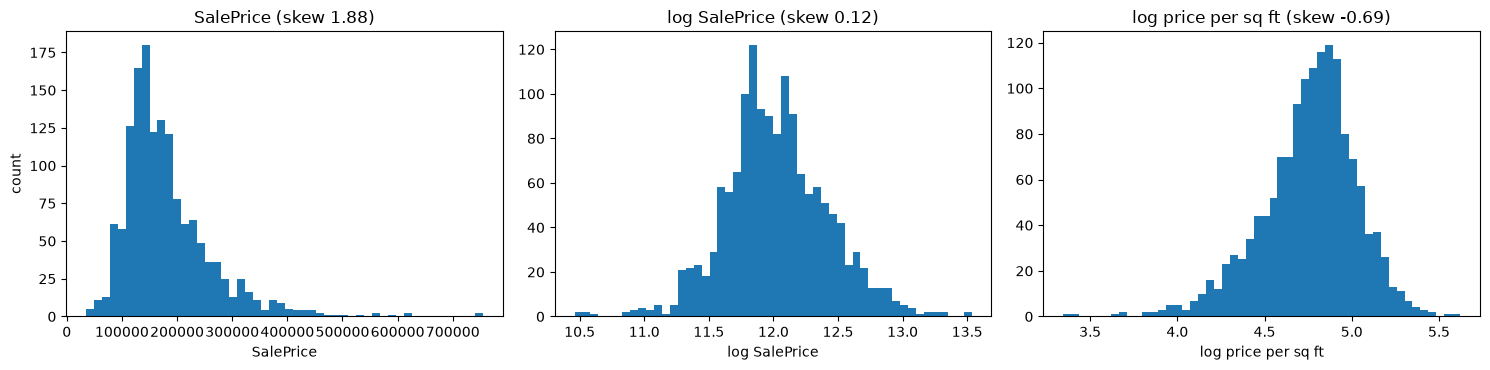

In [5]:
# price per sq ft of above-ground living area: built from the target, so NOT a regressor
df_data['price_psf'] = df_data['SalePrice'] / df_data['GrLivArea']

d_targets = {'SalePrice': df_data['SalePrice'], 'log SalePrice': np.log(df_data['SalePrice']), 'log price per sq ft': np.log(df_data['price_psf'])}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, sl) in zip(axes, d_targets.items()):
    ax.hist(sl, bins=50)
    ax.set_title(f'{name} (skew {sl.skew():.2f})')
    ax.set_xlabel(name)
axes[0].set_ylabel('count')
plt.tight_layout()
plt.show()

Price per sq ft differs a lot between neighbourhoods, and each neighbourhood has a few houses far outside its own range. This supports keeping all 25 `Neighborhood` dummies.

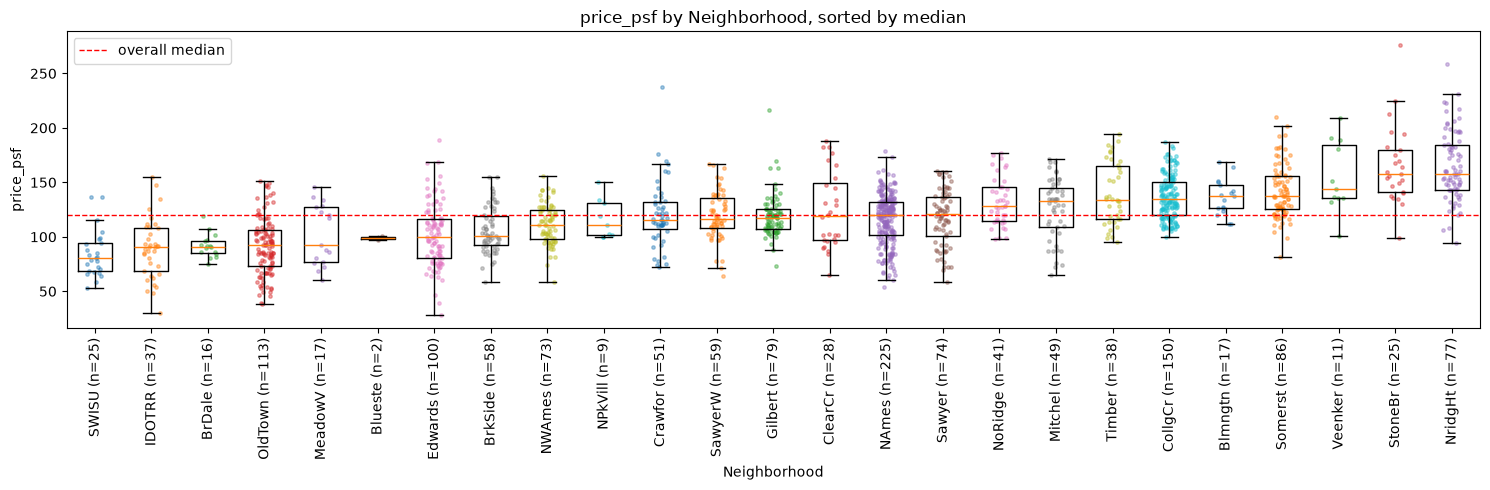

In [6]:
# price per sq ft by neighbourhood: boxplots with every house overlaid
plot_box_strip(df_data, col='price_psf', by='Neighborhood')

## Data cleaning

### Missing values: what NA means

In [7]:
# NA summary across train AND test (features only), split by what NA means for each column
## columns where data_description.txt lists NA as a code, i.e. NA = feature absent (e.g. "NA  No Garage")
l_na_coded = []
col = None
for line in open(ROOT / "data" / "data_description.txt"):
    m = re.match(r'^(\w+):', line)  # column header line, e.g. "Alley: Type of alley access to property"
    if m:
        col = m.group(1)
    elif col and re.match(r'^\s+NA\s', line):  # indented value line for the code NA
        l_na_coded.append(col)

l_features = df_test.columns  # everything except SalePrice
na_summary = pd.DataFrame({
    "na_train": df_data[l_features].isna().sum(),
    "na_test": df_test.isna().sum(),
    "pct_na_train": round(df_data[l_features].isna().mean()*100, 2),
    "pct_na_test": round(df_test.isna().mean()*100, 2),
})
na_summary['na_means'] = np.where(na_summary.index.isin(l_na_coded), 'absent', 'MISSING')
na_summary = na_summary[(na_summary['na_train'] + na_summary['na_test']) > 0]
na_summary.sort_values(['na_means', 'na_train', 'na_test'], ascending=[True, False, False])

,na_train,na_test,pct_na_train,pct_na_test,na_means
LotFrontage,259,227,17.74,15.56,MISSING
GarageYrBlt,81,78,5.55,5.35,MISSING
MasVnrType,8,16,0.55,1.10,MISSING
MasVnrArea,8,15,0.55,1.03,MISSING
Electrical,1,0,0.07,0.00,MISSING
MSZoning,0,4,0.00,0.27,MISSING
Utilities,0,2,0.00,0.14,MISSING
BsmtFullBath,0,2,0.00,0.14,MISSING
BsmtHalfBath,0,2,0.00,0.14,MISSING
Functional,0,2,0.00,0.14,MISSING


### Cleaning NAs

I only look at the columns with NAs in train or test (I didn't write rules for every single feature), one group at a time. 

Each decision falls into one of two kinds:
* Kind A, fixed rules (e.g. NA → `"None"` where the feature is absent, typo fixes, dropping a column): these learn nothing from the data, so they go in a `clean_*(df)` function applied to train and test alike.
* Kind B, learned values (median / mode for genuinely missing values): these are recorded in `d_impute` (column → `SimpleImputer` strategy) and fitted inside the pipeline, so each CV fold learns them from its own training rows.

In [8]:
d_impute = {}  # column -> SimpleImputer strategy for genuinely missing values; filled in group by group below

#### 1. Garage

* Train: `GarageType` is NA exactly where `GarageArea` = 0 (81 rows) → no garage. Test matches, except 2 houses with a detached garage but missing details (Ids 2127, 2577).
* Test Id 2593: `GarageYrBlt` = 2207 (built 2006, remodelled 2007) → typo for 2007.

| # | Decision | Kind |
|---|---|---|
| 1 | `GarageType`/`Finish`/`Qual`/`Cond` NA where `GarageArea` = 0 → `"None"` | A |
| 2 | Drop `GarageYrBlt`: no sensible value for "no garage", and it equals `YearBuilt` in 79% of houses with a garage | A |
| 3 | Id 2593: `GarageYrBlt` 2207 → 2007 (moot while 2 drops the column) | A |
| 4 | Id 2127: missing `Finish`/`Qual`/`Cond` → mode | B |
| 5 | Id 2577: treat as having a garage; `Finish`/`Qual`/`Cond` → mode, `Cars`/`Area` → median | B |

In [9]:
# garage: kind-A rules (fixed, safe on train and test alike) + kind-B decisions (learned in the pipeline)
l_garage_cat = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
l_garage_num = ['GarageCars', 'GarageArea']

def clean_garage(df):
    df = df.copy()
    no_garage = df['GarageArea'] == 0  # NaN area (test Id 2577) is NOT counted as "no garage"
    df.loc[no_garage, l_garage_cat] = df.loc[no_garage, l_garage_cat].fillna('None')  # 1. NA = no garage
    df['GarageYrBlt'] = df['GarageYrBlt'].replace(2207, 2007)  # 3. typo (test Id 2593); moot while 2. drops the column
    return df.drop(columns=['GarageYrBlt'])  # 2. mostly repeats YearBuilt (equal in 79% of houses with a garage)

# 4, 5(a). genuinely missing (test Ids 2127, 2577): imputed in the pipeline from the training data
d_impute.update({c: 'most_frequent' for c in ['GarageFinish', 'GarageQual', 'GarageCond']})
d_impute.update({c: 'median' for c in l_garage_num})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_garage(df)
    df_left = df_c.loc[df_c[l_garage_cat + l_garage_num].isna().any(axis=1), ['Id'] + l_garage_cat + l_garage_num]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 0 rows left for the imputer


,Id,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea


test: 2 rows left for the imputer


,Id,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea
666,2127,Detchd,NaN,NaN,NaN,1.0,360.0
1116,2577,Detchd,NaN,NaN,NaN,NaN,NaN


#### 2. Basement

* Train: all 37 houses with `TotalBsmtSF` = 0 have all 5 basement categoricals NA → no basement. Test: same for its 41, plus Id 2121, where *every* basement field is NA (the categoricals agree it has none). Test Id 2189 has no basement but NA bath counts.
* Genuinely missing (house has a basement): train 949 (`Exposure`), 333 (`FinType2`); test 1488, 2349 (`Exposure`), 2218, 2219 (`Qual`), 2041, 2186, 2525 (`Cond`).

| # | Decision | Kind |
|---|---|---|
| 1 | No basement (`TotalBsmtSF` = 0, or every basement field NA): 5 categoricals → `"None"`, SF and bath counts → 0 | A |
| 2 | Remaining categorical NAs → mode | B |
| 3 | Id 333's `BsmtFinType2` → plain mode (`Unf`) | B |

On 3: strictly, `Unf` contradicts Id 333's `BsmtFinSF2` = 479. A more faithful fill would be the mode among houses with `BsmtFinSF2` > 0, but that adds complexity. Since it's the only such conflict (one row across train and test), the plain mode is kept for simplicity; I'd expect a negligible impact on the final model. 

In [10]:
# basement: kind-A rules (fixed, safe on train and test alike) + kind-B decisions (learned in the pipeline)
l_bsmt_cat = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
l_bsmt_num = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']

def clean_basement(df):
    df = df.copy()
    no_bsmt = (df['TotalBsmtSF'] == 0) | df[l_bsmt_cat + l_bsmt_num].isna().all(axis=1)  # 2nd part: test Id 2121, every basement field NA
    df.loc[no_bsmt, l_bsmt_cat] = df.loc[no_bsmt, l_bsmt_cat].fillna('None')  # 1. NA = no basement
    df.loc[no_bsmt, l_bsmt_num] = df.loc[no_bsmt, l_bsmt_num].fillna(0)  # 1. no basement = 0 sq ft, 0 baths
    return df

# 2, 3(a). genuinely missing categoricals (houses that do have a basement): mode, imputed in the pipeline
d_impute.update({c: 'most_frequent' for c in l_bsmt_cat})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_basement(df)
    df_left = df_c.loc[df_c[l_bsmt_cat + l_bsmt_num].isna().any(axis=1), ['Id'] + l_bsmt_cat + ['TotalBsmtSF']]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 2 rows left for the imputer


,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
332,333,Gd,TA,No,GLQ,NaN,3206
948,949,Gd,TA,NaN,Unf,Unf,936


test: 7 rows left for the imputer


,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
27,1488,Gd,TA,NaN,Unf,Unf,1595.0
580,2041,Gd,NaN,Mn,GLQ,Rec,1426.0
725,2186,TA,NaN,No,BLQ,Unf,1127.0
757,2218,NaN,Fa,No,Unf,Unf,173.0
758,2219,NaN,TA,No,Unf,Unf,356.0
888,2349,Gd,TA,NaN,Unf,Unf,725.0
1064,2525,TA,NaN,Av,ALQ,Unf,995.0


#### 3. Masonry veneer

* Both columns NA: 8 train, 15 test. Test Id 2611: type NA but area 198.
* Contradictions: `"None"` with area 1 (train 774, 1231; test 2453 - a placeholder), `"None"` with real area (train 625, 1301, 1335; test 1670), type set with area 0 (train 689, 1242; test 2320).

Main principle: take the area as the true value.

| # | Decision | Kind |
|---|---|---|
| 1 | Both NA → type mode, area median (on train: `"None"`, 0 = no veneer) | B |
| 2 | Area $\le 1$ → type `"None"`, area 0 | A |
| 3 | Area > 1 but type `"None"`/NA → `"BrkFace"` (most common veneer type in train: 445 vs Stone 128) | A |

Unlike basement Id 333, a plain mode for 3 would leave contradictions in *test* rows (1670, 2611), which feed straight into their predictions.

In [11]:
# masonry veneer: kind-A rules ("trust the area") + kind-B decisions (learned in the pipeline)
l_mvnr = ['MasVnrType', 'MasVnrArea']

def clean_masonry(df):
    df = df.copy()
    no_vnr = df['MasVnrArea'] <= 1  # 2. area 0, or a 1-sq-ft placeholder = no veneer (NaN area isn't touched: left for the imputer)
    df.loc[no_vnr, 'MasVnrType'] = 'None'
    df.loc[no_vnr, 'MasVnrArea'] = 0
    has_vnr = (df['MasVnrArea'] > 1) & (df['MasVnrType'].isna() | (df['MasVnrType'] == 'None'))
    df.loc[has_vnr, 'MasVnrType'] = 'BrkFace'  # 3. real veneer but type missing / "None" -> most common veneer type in train
    return df

# 1. both columns NA: imputed in the pipeline (on train: mode "None", median 0 = no veneer)
d_impute.update({'MasVnrType': 'most_frequent', 'MasVnrArea': 'median'})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_masonry(df)
    n_left = df_c[l_mvnr].isna().any(axis=1).sum()
    n_conflict = (((df_c['MasVnrType'] == 'None') & (df_c['MasVnrArea'] > 0)) | ((df_c['MasVnrType'] != 'None') & (df_c['MasVnrArea'] == 0))).sum()
    print(f'{name}: {n_left} rows left for the imputer, {n_conflict} type/area contradictions left')

train: 8 rows left for the imputer, 0 type/area contradictions left
test: 15 rows left for the imputer, 0 type/area contradictions left


#### 4. Pool, Misc, Fireplace, Alley, Fence

* `FireplaceQu` is NA exactly where `Fireplaces` = 0 (train and test). `Alley` and `Fence` have no companion column, so nothing can contradict them.
* `PoolQC`: only 7 pools in train; test 2421, 2504, 2600 have `PoolArea` > 0 but `PoolQC` NA.
* `MiscFeature`: test 2550 has `MiscVal` = $17,000 but the feature NA; train 874, 1201 and test 2432 have a feature but `MiscVal` = 0.

| # | Decision | Kind |
|---|---|---|
| 1 | `FireplaceQu`, `Alley`, `Fence`: NA → `"None"`, keep. Despite > 80% NA (slides' drop rule), the NAs mean "absent", not unknown. | A |
| 2 | **Drop** `PoolQC`: `PoolArea` already says whether there's a pool and how big; 7 pools are too few to learn from; it also removes the 3 test contradictions | A |
| 3 | **Drop** `MiscFeature`: `MiscVal` carries the dollar value; removes Id 2550's contradiction and the 3 "feature but $0" rows | A |

In [12]:
# fireplace, alley, fence, pool, misc: kind-A rules only
l_na_absent = ['FireplaceQu', 'Alley', 'Fence']

def clean_extras(df):
    df = df.copy()
    df[l_na_absent] = df[l_na_absent].fillna('None')  # 1. NA = no fireplace / alley access / fence (no contradictions in train or test)
    return df.drop(columns=['PoolQC', 'MiscFeature'])  # 2, 3. PoolArea and MiscVal already carry the information

## check: no NaNs should be left in these columns
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_extras(df)
    print(f"{name}: {df_c[l_na_absent + ['PoolArea', 'MiscVal']].isna().sum().sum()} NaNs left")

train: 0 NaNs left
test: 0 NaNs left


#### 5. LotFrontage

* Genuinely missing (NA isn't a code): 259 train (17.7%), 227 test. Not at random: 52% of cul-de-sac lots are missing vs 13% of inside lots.


| # | Decision | Kind |
|---|---|---|
| 1 | **Drop `LotFrontage`** | A |

Why: it's hard to interpret consistently. A corner lot can have double or triple the frontage of an otherwise identical house (cul-de-sac lots are the opposite case), so there's too much to normalise against. `LotArea` already carries the lot-size information.

Other options considered: overall median (+ missing indicator), median by `Neighborhood`, regression on $\sqrt{\texttt{LotArea}}$, or drop.

In [13]:
# lot frontage: kind-A rule only
def clean_lotfrontage(df):
    return df.drop(columns=['LotFrontage'])  # 1. too many interpretations (corner / cul-de-sac lots); LotArea covers lot size

#### 6. One-off missing values

`Electrical` (train Id 1380); test only: `MSZoning` (1916, 2217, 2251, 2905), `Utilities` (1916, 1946), `Functional` (2217, 2474), `Exterior1st`/`2nd` (2152), `KitchenQual` (1556), `SaleType` (2490).

| # | Decision | Kind |
|---|---|---|
| 1 | Drop `Utilities`: train has 1,459 `AllPub` and 1 `NoSeWa`, test is all `AllPub`, so it isn't informative | A |
| 2 | `Functional` NA → `"Typ"`, per data_description: "Assume typical unless deductions are warranted" | A |
| 3 | `Electrical`, `Exterior1st`/`2nd`, `KitchenQual`, `SaleType` → mode | B |
| 4 | `MSZoning` → plain mode (`RL`) | B |

On 4: zoning matters for price (train medians: RL \$174k, RM \$120.5k, C \$74.7k), and three of the four houses (1916, 2217, 2251) are in IDOTRR, where **no** training house is RL (28 RM, 9 C). So the plain mode knowingly gives them a zoning class their neighbourhood doesn't have, which will likely push their predictions up. The alternative was the neighbourhood's mode (IDOTRR → `RM`). Plain mode is kept for now for simplicity; it only affects these three test predictions. Revisit if needed.

In [14]:
# one-off missing values: kind-A rules + kind-B decisions (learned in the pipeline)
l_oneoff_mode = ['Electrical', 'Exterior1st', 'Exterior2nd', 'KitchenQual', 'SaleType', 'MSZoning']

def clean_oneoffs(df):
    df = df.copy()
    df['Functional'] = df['Functional'].fillna('Typ')  # 2. data_description: "Assume typical unless deductions are warranted"
    return df.drop(columns=['Utilities'])  # 1. 1 non-AllPub house in 2,919: not informative

# 3, 4. genuinely missing: mode, imputed in the pipeline (MSZoning: plain mode, knowingly - see the note above)
d_impute.update({c: 'most_frequent' for c in l_oneoff_mode})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_oneoffs(df)
    df_left = df_c.loc[df_c[l_oneoff_mode + ['Functional']].isna().any(axis=1), ['Id', 'Neighborhood'] + l_oneoff_mode]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 1 rows left for the imputer


,Id,Neighborhood,Electrical,Exterior1st,Exterior2nd,KitchenQual,SaleType,MSZoning
1379,1380,Timber,NaN,VinylSd,VinylSd,Gd,WD,RL


test: 7 rows left for the imputer


,Id,Neighborhood,Electrical,Exterior1st,Exterior2nd,KitchenQual,SaleType,MSZoning
95,1556,ClearCr,SBrkr,Wd Sdng,Wd Sdng,NaN,COD,RL
455,1916,IDOTRR,FuseA,Wd Sdng,Wd Sdng,TA,ConLD,NaN
691,2152,Edwards,SBrkr,NaN,NaN,Fa,WD,RL
756,2217,IDOTRR,FuseA,AsbShng,VinylSd,Fa,WD,NaN
790,2251,IDOTRR,SBrkr,Wd Sdng,Wd Sdng,TA,WD,NaN
1029,2490,Sawyer,SBrkr,Plywood,Plywood,TA,NaN,RL
1444,2905,Mitchel,FuseA,CBlock,VinylSd,TA,WD,NaN


### Types

| # | Decision | Kind |
|---|---|---|
| 1 | `MSSubClass` → text (`"SC20"`, `"SC60"`, …): it's a dwelling-type code, not a quantity. Test has one level not in train (`SC150`, 1 house). The encoders set all its `MSSubClass` dummies to 0, which naive++ reads as the baseline level and the penalised models (no baseline) as the average house | A |
| 2 | The 9 Ex/Gd/TA/Fa/Po columns (`ExterQual`, `ExterCond`, `BsmtQual`, `BsmtCond`, `HeatingQC`, `KitchenQual`, `FireplaceQu`, `GarageQual`, `GarageCond`) → 0–5 (`None` = 0, `Po` = 1, …, `Ex` = 5): keeps the order, 1 column each instead of ~5 dummies | A |
| 3 | `MoSold` + `YrSold` → `sale_date` = 1st of the sale month, in years (e.g. 2008.25 = 1 Apr 2008); drop the two columns | A |

In [15]:
# types: kind-A rules (fixed, safe on train and test alike)
l_qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']
d_qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

def clean_types(df):
    df = df.copy()
    df['MSSubClass'] = 'SC' + df['MSSubClass'].astype(str)  # 1. a dwelling-type code, not a quantity (prefix so it never looks numeric)
    for c in l_qual_cols:  # 2. ordered quality scale -> 0-5; NaN stays NaN for the imputer (its mode then works on the numbers)
        assert df[c].dropna().isin(list(d_qual_map)).all(), f'unexpected level in {c}'
        df[c] = df[c].map(d_qual_map)
    df['sale_date'] = df['YrSold'] + (df['MoSold'] - 1) / 12  # 3. 1st of the sale month, in years (e.g. 2008.25 = 1 Apr 2008)
    return df.drop(columns=['MoSold', 'YrSold'])

### Living-area columns: not model inputs

`GrLivArea` and its three parts, `1stFlrSF`, `2ndFlrSF` and `LowQualFinSF` (which add up to `GrLivArea` exactly, in train and test), are kept in the data but are **not** model inputs. The target is price per sq ft, so size is already divided out of it. The models should explain how expensive a house is *per square foot* from what the house is like (location, quality, age, …), without size coming back in as a regressor.

* `GrLivArea` is still used to build the target and to convert predictions back to prices.
* The columns are removed in `add_features` (switches `ui_drop_grlivarea` and `ui_drop_area_parts`), so the cleaning steps above are unchanged.
* `has_2ndflr` (whether the house has a second floor) stays.

### Outliers

Two rules, applied to the training rows of each fit only: inside every CV fold and in the final refit. Validation and test rows are not dropped.

1. Huge partial sales: `GrLivArea` > 4,000 and `SaleCondition` == `'Partial'` → Ids 524 and 1299. These are the two biggest houses, with quality 10, yet they sold for about half the median price. This is a **fixed rule**, and the 4,000 sq ft cut-off isn't sensitive since no training house lies between 3,627 and 4,316 sq ft.
2. Neighbourhood psf boxplot whiskers: houses outside their neighbourhood's boxplot whiskers on price per sq ft ($Q_1 - 1.5\,\text{IQR}$, $Q_3 + 1.5\,\text{IQR}$), for neighbourhoods with more than 10 houses (the boxplots above).

Note that running the rules inside each fit means cross-validation still scores all 1,460 training houses, outliers included.

In [16]:
# outliers: two rounds, applied to the TRAINING rows of each fit only (inside every fit_predict / CV fold), never to validation or test rows
ui_outlier_rounds = (1, 2)  # 1 = huge partial sales; 2 = outside the neighbourhood's psf whiskers; () = drop nothing (to compare by CV)
ui_big_sqft = 4000  # round 1: GrLivArea above this AND a partial sale (no training house lies between 3,627 and 4,316 sq ft)
ui_outlier_col = 'price_psf'  # round 2 on 'price_psf' (the target) or 'SalePrice'
ui_outlier_min_n = 10  # round 2 only for neighbourhoods with more than this many houses: small ones have unreliable quartiles

def flag_outliers(df_X, sl_price, rounds=ui_outlier_rounds, col=ui_outlier_col, min_n=ui_outlier_min_n):
    """True for the training houses to drop. Round 1: huge partial sales (fixed rule). Round 2: outside their neighbourhood's
    1.5 x IQR whiskers on col (same rule as the boxplots), with the quartiles learned from the rows left after round 1."""
    sl_drop = pd.Series(False, index=df_X.index)
    if 1 in rounds:
        sl_drop |= (df_X['GrLivArea'] > ui_big_sqft) & (df_X['SaleCondition'] == 'Partial')
    if 2 in rounds:
        df_k, sl_k = df_X[~sl_drop], sl_price[~sl_drop]
        sl = sl_k / df_k['GrLivArea'] if col == 'price_psf' else sl_k
        grp = sl.groupby(df_k['Neighborhood'])
        q1, q3 = grp.transform(lambda s: s.quantile(0.25)), grp.transform(lambda s: s.quantile(0.75))
        sl_out2 = (grp.transform('size') > min_n) & ((sl < q1 - 1.5 * (q3 - q1)) | (sl > q3 + 1.5 * (q3 - q1)))
        sl_drop |= sl_out2.reindex(df_X.index, fill_value=False)
    return sl_drop

def drop_outliers(df_X, sl_price):
    """The training rows of one fit with the outliers dropped. Call it at the start of every fit; validation and test rows are never dropped."""
    sl_drop = flag_outliers(df_X, sl_price)
    return df_X[~sl_drop], sl_price[~sl_drop]

df_train = df_data  # all 1,460 training houses: every one is scored in CV; outliers leave only the rows a model is fitted on

## which houses the rules flag on all 1,460 (inside CV, each fold's 80% gets its own quartiles, so the list can differ slightly)
sl_outlier = flag_outliers(df_data, df_data['SalePrice'])
sl_round1 = flag_outliers(df_data, df_data['SalePrice'], rounds=(1,))
print(f'flagged {sl_outlier.sum()} of {len(df_data)} training houses: round 1 {sl_round1.sum()}, round 2 {(sl_outlier & ~sl_round1).sum()} (rounds {ui_outlier_rounds})')
df_data.loc[sl_outlier, ['Id', 'Neighborhood', 'GrLivArea', 'SalePrice', 'SaleCondition']].assign(
    price_psf=lambda x: (x['SalePrice'] / x['GrLivArea']).round(0), round=np.where(sl_round1[sl_outlier], 1, 2)).sort_values(['round', 'Neighborhood', 'price_psf'])

flagged 20 of 1460 training houses: round 1 2, round 2 18 (rounds (1, 2))


,Id,Neighborhood,GrLivArea,SalePrice,SaleCondition,price_psf,round
1298,1299,Edwards,5642,160000,Partial,28.0,1
523,524,Edwards,4676,184750,Partial,40.0,1
363,364,BrDale,987,118000,Normal,120.0,2
92,93,Crawfor,964,163500,Normal,170.0,2
1310,1311,Crawfor,1902,335000,Normal,176.0,2
1181,1182,Crawfor,1652,392500,Partial,238.0,2
724,725,Edwards,1698,320000,Normal,188.0,2
868,869,Gilbert,2320,169000,Normal,73.0,2
277,278,Gilbert,864,141000,Normal,163.0,2
1258,1259,Gilbert,1166,190000,Normal,163.0,2


## Preprocessing pipelines

* **Fixed rules:** `clean(df)` chains the `clean_*` functions above (NA groups 1–6 + types). It learns nothing from the data, so it's applied to train and test directly.
* **Learned steps:** `imputer` (one `SimpleImputer` per strategy and text/numeric group in `d_impute`) → `add_features` (engineered features, fixed formulas) → one-hot encoding (+ scaling for the penalised models). These sit **inside** each model's pipeline, so every CV fold learns its own medians, modes, categories, means and SDs from its own training rows.
* `df_X_train` (all 1,460 training houses; outliers are dropped inside each fit) and `df_X_test` hold the features only: no `Id`, no `SalePrice`, no `price_psf`.

In [17]:
# combine: all kind-A rules in one function, applied to train and test alike
def clean(df):
    for f in [clean_garage, clean_basement, clean_masonry, clean_extras, clean_lotfrontage, clean_oneoffs, clean_types]:
        df = f(df)
    return df

l_features = [c for c in clean(df_test).columns if c != 'Id']  # features only: no Id, no SalePrice, no columns added to df_data later (e.g. price_psf)
df_X_train = clean(df_train)[l_features]  # all 1,460 training houses (outliers are dropped inside each fit, not here)
df_X_test = clean(df_test)[l_features]

## check: after clean(), the only NaNs left should be in d_impute's columns
for name, df in [('train', df_X_train), ('test', df_X_test)]:
    sl_na = df.isna().sum()[lambda s: s > 0]
    l_unplanned = [c for c in sl_na.index if c not in d_impute]
    print(f'{name}: {sl_na.sum()} NaNs in {len(sl_na)} columns; not covered by d_impute: {l_unplanned}')

train: 19 NaNs in 5 columns; not covered by d_impute: []
test: 53 NaNs in 15 columns; not covered by d_impute: []


In [18]:
# kind-B: one SimpleImputer per (strategy, text/numeric) group of d_impute's columns; all other columns pass through unchanged
# (text and numeric columns get separate imputers: a mixed group would come out as text, and the encoder would then one-hot the numbers)
l_text_cols = df_X_train.select_dtypes(exclude='number').columns
d_groups = {}
for c, strategy in d_impute.items():
    d_groups.setdefault(f"{strategy}_{'text' if c in l_text_cols else 'num'}", (strategy, []))[1].append(c)

imputer = ColumnTransformer(
    [(name, SimpleImputer(strategy=strategy), l_cols) for name, (strategy, l_cols) in d_groups.items()],
    remainder='passthrough',
    verbose_feature_names_out=False,  # keep the original column names
).set_output(transform='pandas')

## check: fit on all of train (in CV, the pipeline refits this per fold), transform both -> no NaNs left
df_X_train_imp = imputer.fit_transform(df_X_train)
df_X_test_imp = imputer.transform(df_X_test)
print('NaNs left: train', df_X_train_imp.isna().sum().sum(), '| test', df_X_test_imp.isna().sum().sum())
print('shapes:', df_X_train_imp.shape, df_X_test_imp.shape)
print('columns whose dtype changed:', [c for c in df_X_train.columns if (c in l_text_cols) != (c in df_X_train_imp.select_dtypes(exclude='number').columns)])

## the values learned from train
pd.DataFrame([
    {'column': c, 'strategy': name, 'fill value': v}
    for name, step, l_cols in imputer.transformers_ if name != 'remainder'
    for c, v in zip(l_cols, step.statistics_)
])

NaNs left: train 0 | test 0
shapes: (1460, 73) (1459, 73)
columns whose dtype changed: []


,column,strategy,fill value
0,GarageFinish,most_frequent_text,Unf
1,BsmtExposure,most_frequent_text,No
2,BsmtFinType1,most_frequent_text,Unf
3,BsmtFinType2,most_frequent_text,Unf
4,MasVnrType,most_frequent_text,None
5,Electrical,most_frequent_text,SBrkr
6,Exterior1st,most_frequent_text,VinylSd
7,Exterior2nd,most_frequent_text,VinylSd
8,SaleType,most_frequent_text,WD
9,MSZoning,most_frequent_text,RL


### Engineered features

The same engineered features are used by every model, so the comparison is fair:
* `log_LotArea` replaces `LotArea` (skewed, no zeros). 
* `has_*` flags (0/1) for 10 things a house may not have: a 2nd floor, basement, garage, fireplace, masonry veneer, wood deck, porch, pool, misc feature, or remodel. 
  * So "none" gets its own jump instead of being scored as the bottom of a scale. 
  * For example, the 0–5 quality maps score "no basement" as 0, one step below Poor.
* $\log(1 + x)$ for the columns that contain lots of zeros. Pool and misc keep only their flags: a slope estimated from 7 pools is noise.
* `OverallQual_sq` - squared because mean log psf rises faster at higher quality (steps of +0.02, +0.09, +0.15, +0.22 from quality 5 to 9, on all 1,460 training houses). `OverallCond` stays linear. Its raw peak at 5 is an age effect, since new houses are rated 5; holding `YearBuilt` and `OverallQual` fixed, it is about linear.

In [19]:
# kind-A feature engineering: fixed formulas, run INSIDE both preprocessing pipelines right after the imputer, so every model
# (OLS and penalised) gets the same candidate features. After the imputer there are no NaNs left, and df_X itself keeps the raw
# GrLivArea that the target (psf = price / GrLivArea) and the conversion back to price need
ui_drop_grlivarea = True  # True: GrLivArea is not a model input; it only defines the target and converts it back to price
ui_drop_area_parts = True  # True: 1stFlrSF, 2ndFlrSF, LowQualFinSF (which sum to GrLivArea exactly) aren't model inputs either; has_2ndflr stays

def add_features(df):
    """The engineered model inputs (kind A: nothing is learned from the data). Flags are named has_* and are 0/1, like the dummies."""
    df = df.copy()

    ## skewed sizes with no zeros: replaced by their logs (LotArea skew 12.2 -> -0.1)
    df['log_LotArea'] = np.log(df.pop('LotArea'))
    sl_grlivarea = df.pop('GrLivArea')  # df_X keeps GrLivArea: the target (psf = price / GrLivArea) and the conversion back to price use it there
    if not ui_drop_grlivarea:
        df['log_GrLivArea'] = np.log(sl_grlivarea)

    ## has-it flags: "none" gets its own jump instead of being scored as the bottom of a scale
    ## (the 0-5 quality maps score no basement / garage / fireplace as 0, one step below Poor)
    sl_porch = df[['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']].sum(axis=1)
    d_flags = {
        'has_2ndflr': df['2ndFlrSF'], 'has_bsmt': df['TotalBsmtSF'], 'has_garage': df['GarageArea'],
        'has_fireplace': df['Fireplaces'], 'has_masvnr': df['MasVnrArea'], 'has_wooddeck': df['WoodDeckSF'],
        'has_porch': sl_porch, 'has_pool': df['PoolArea'], 'has_misc': df['MiscVal'],
        'has_remodel': df['YearRemodAdd'] - df['YearBuilt'],
    }
    for name, sl in d_flags.items():
        df[name] = (sl > 0).astype(int)

    ## zero-inflated areas: log(1 + x) keeps the zeros at 0; pool and misc keep only their flags
    ## (a slope from 7 pools is noise; MiscVal is dollars, driven by two extremes of $8,300 and $15,500)
    for c in ['MasVnrArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'BsmtFinSF1', 'BsmtFinSF2']:
        df[f'log1p_{c}'] = np.log1p(df.pop(c))
    df = df.drop(columns=['PoolArea', 'MiscVal'])

    ## curvature: mean log psf steps +0.02, +0.09, +0.15, +0.22 from quality 5 to 9 (all 1,460 training houses)
    ## (OverallCond stays linear: its raw peak at 5 is an age effect, since new houses get a 5; holding YearBuilt and OverallQual fixed it's ~linear)
    df['OverallQual_sq'] = df['OverallQual'] ** 2

    ## GrLivArea's parts: dropped last, after has_2ndflr has been read off 2ndFlrSF
    if ui_drop_area_parts:
        df = df.drop(columns=['1stFlrSF', '2ndFlrSF', 'LowQualFinSF'])
    return df

features = FunctionTransformer(add_features)  # a pipeline step: preprocess and make_preprocess_reg both run it after the imputer

Why `OverallQual_sq`: between quality 5 and 9, where most houses are, mean log psf rises faster at higher quality (steps of +0.02, +0.09, +0.15, +0.22). Against `OverallQual` these means bend upwards; against `OverallQual`$^2$ they lie closer to a straight line. The extremes have few houses (2, 3 and 20 at quality 1–3; 18 at quality 10, including the two huge partial sales 524 and 1299), and they pull the straight-line fits around. So the overall $R^2$ barely changes (0.194 vs 0.195), and the case for the square rests on the middle of the scale.

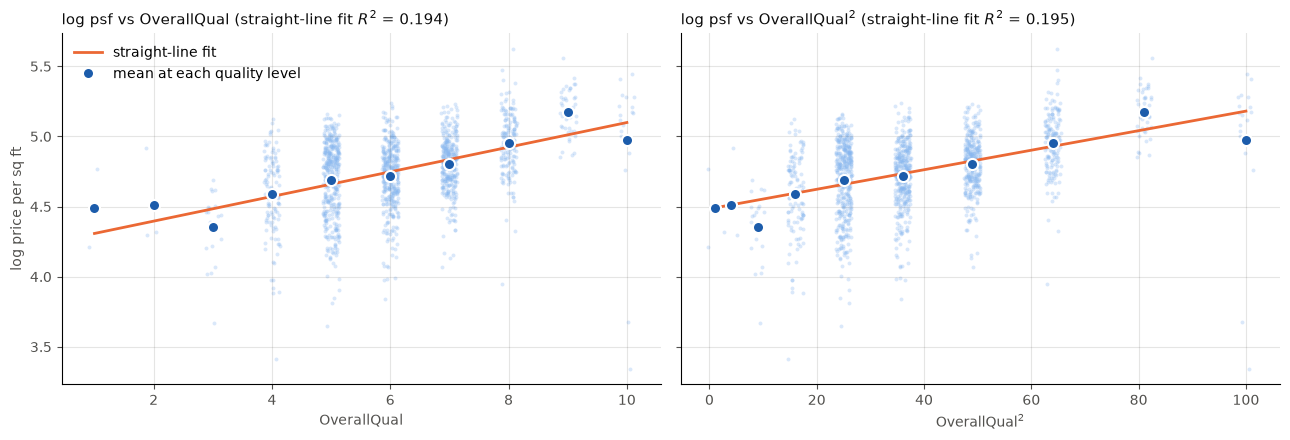

In [20]:
# log price per sq ft against OverallQual (left) and OverallQual² (right), all 1,460 training houses
# dots = houses (jittered sideways), large dots = the mean at each quality level, line = a straight-line OLS fit of log psf on the x-axis
sl_y = np.log(df_data['price_psf'])
rng = np.random.default_rng(42)  # fixed jitter
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (label, sl_x) in zip(axes, [('OverallQual', df_data['OverallQual']), ('OverallQual$^2$', df_data['OverallQual'] ** 2)]):
    res = sm.OLS(sl_y, sm.add_constant(sl_x)).fit()
    sl_mean = sl_y.groupby(sl_x).mean()
    jitter = 0.15 * (sl_x.max() - sl_x.min()) / sl_x.nunique()
    ax.scatter(sl_x + rng.uniform(-jitter, jitter, len(sl_x)), sl_y, s=8, alpha=0.3, color='#86b6ef', linewidths=0)
    x_grid = np.linspace(sl_x.min(), sl_x.max(), 100)
    ax.plot(x_grid, res.params.iloc[0] + res.params.iloc[1] * x_grid, color='#eb6834', linewidth=2, label='straight-line fit')
    ax.plot(sl_mean.index, sl_mean.values, 'o', color='#1c5cab', markersize=8, markeredgecolor='white', markeredgewidth=1.5, label='mean at each quality level')
    ax.set_title(f'log psf vs {label} (straight-line fit $R^2$ = {res.rsquared:.3f})', loc='left', fontsize=11, color='#0b0b0b')
    ax.set_xlabel(label, color='#52514e')
    ax.grid(color='#52514e', alpha=0.15, linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors='#52514e')
axes[0].set_ylabel('log price per sq ft', color='#52514e')
axes[0].legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

### Encoding: OLS vs penalised models

* OLS (naive++): one-hot with `drop='first'`, so one level per column is the baseline. This avoids the dummy trap (perfect collinearity with the intercept). Scaling isn't needed, because OLS predictions don't depend on it.
* Lasso / Ridge / Elastic Net:
  * Numeric columns are standardised, because the penalty compares coefficient sizes, which only means something on a common scale.
  * One-hot uses `drop=None` (every level kept). With a baseline, the penalty would pull every level towards whichever level happens to come first alphabetically. Without one, it pulls each level towards the average house.
  * The dummies and `has_*` flags stay 0/1, so a coefficient is still "the effect of having it". Standardising a rare 0/1 column would inflate its values, which changes how strongly the penalty shrinks it.

In [21]:
# kind-B: one-hot encode every text column (the encoder learns each column's categories in fit); numeric columns pass through
encoder = ColumnTransformer(
    [('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), make_column_selector(dtype_exclude='number'))],
    remainder='passthrough',
    verbose_feature_names_out=False,  # dummies named like MSZoning_RL; numeric columns keep their names
).set_output(transform='pandas')
# drop='first': one level per column becomes the baseline, avoiding the dummy trap (perfect collinearity with the intercept) in OLS
# handle_unknown='ignore': a level never seen in training becomes all zeros (i.e. treated like the baseline) instead of an error

preprocess = Pipeline([('impute', imputer), ('features', features), ('encode', encoder)])  # goes at the front of the model pipeline

## check: fit on all of train (in CV, the model pipeline refits this per fold), transform both
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')  # test's SC150 (not in train) -> all zeros = the baseline
    df_X_train_enc = preprocess.fit_transform(df_X_train)
    df_X_test_enc = preprocess.transform(df_X_test)
print('shapes:', df_X_train_enc.shape, df_X_test_enc.shape, '| NaNs left:', df_X_train_enc.isna().sum().sum(), df_X_test_enc.isna().sum().sum())
print('non-numeric columns left:', list(df_X_train_enc.select_dtypes(exclude='number').columns))
df_X_train_enc.head()

shapes: (1460, 238) (1459, 238) | NaNs left: 0 0
non-numeric columns left: []


,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,BsmtExposure_Gd,BsmtExposure_Mn,BsmtExposure_No,BsmtExposure_None,BsmtFinType1_BLQ,BsmtFinType1_GLQ,BsmtFinType1_LwQ,...,has_remodel,log1p_MasVnrArea,log1p_WoodDeckSF,log1p_OpenPorchSF,log1p_EnclosedPorch,log1p_3SsnPorch,log1p_ScreenPorch,log1p_BsmtFinSF1,log1p_BsmtFinSF2,OverallQual_sq
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0,5.283204,0.000000,4.127134,0.000000,0.0,0.0,6.561031,0.0,49
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.000000,5.700444,0.000000,0.000000,0.0,0.0,6.886532,0.0,36
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1,5.093750,0.000000,3.761200,0.000000,0.0,0.0,6.188264,0.0,49
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1,0.000000,0.000000,3.583519,5.609472,0.0,0.0,5.379897,0.0,49
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0,5.860786,5.262690,4.442651,0.000000,0.0,0.0,6.486161,0.0,64


In [22]:
# kind-B, for the penalised models (Lasso / Ridge / Elastic Net): impute -> one-hot with NO baseline -> standardise the numeric columns
# (preprocess above stays as it is for the OLS models: OLS needs a baseline, and its predictions don't depend on scaling)
def make_preprocess_reg(scale_dummies=False):
    """Fresh (unfitted) preprocessing pipeline for penalised models.
    drop=None: keep every level, so the penalty pulls each level towards the average house, not towards an alphabetical baseline.
    Numeric columns are always standardised (the penalty must compare like with like); dummies and the has_* flags stay 0/1
    unless scale_dummies=True."""
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)  # drop=None (the default); unknown level -> all zeros = the average house
    dummies = Pipeline([('onehot', onehot), ('scale', StandardScaler())]) if scale_dummies else onehot
    l_parts = [('onehot', dummies, make_column_selector(dtype_exclude='number'))]
    if not scale_dummies:
        l_parts.append(('flags', 'passthrough', make_column_selector(pattern='^has_')))  # 0/1 like the dummies: left unscaled too
    encoder_reg = ColumnTransformer(
        l_parts,
        remainder=StandardScaler(),  # the numeric columns: mean 0, sd 1, learned from the training rows
        verbose_feature_names_out=False,
    ).set_output(transform='pandas')
    return Pipeline([('impute', clone(imputer)), ('features', clone(features)), ('encode', encoder_reg)])

## check: fit on all of train (in CV, each fit_predict builds a fresh one per fold), transform both
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    pre_reg = make_preprocess_reg()
    df_X_train_reg = pre_reg.fit_transform(df_X_train)
    df_X_test_reg = pre_reg.transform(df_X_test)
l_dummy_cols = list(pre_reg.named_steps['encode'].named_transformers_['onehot'].get_feature_names_out())
l_flag_cols = [c for c in df_X_train_reg.columns if c.startswith('has_')]
l_num_cols = [c for c in df_X_train_reg.columns if c not in l_dummy_cols + l_flag_cols]
df_num = df_X_train_reg[l_num_cols]
print('shapes:', df_X_train_reg.shape, df_X_test_reg.shape, '| NaNs left:', df_X_train_reg.isna().sum().sum(), df_X_test_reg.isna().sum().sum())
print(f'numeric columns on train: means {df_num.mean().abs().max():.1e} at most, sds {df_num.std(ddof=0).min():.3f} to {df_num.std(ddof=0).max():.3f}')
print('dummies and flags still 0/1:', df_X_train_reg[l_dummy_cols + l_flag_cols].isin([0, 1]).all().all(), f'| {len(l_dummy_cols)} dummies, {len(l_flag_cols)} flags, {len(l_num_cols)} scaled numeric columns')
print('flags, share of houses with each:', df_X_train_reg[l_flag_cols].mean().round(2).to_dict())

shapes: (1460, 270) (1459, 270) | NaNs left: 0 0
numeric columns on train: means 7.0e-14 at most, sds 1.000 to 1.000
dummies and flags still 0/1: True | 224 dummies, 10 flags, 36 scaled numeric columns
flags, share of houses with each: {'has_2ndflr': 0.43, 'has_bsmt': 0.97, 'has_garage': 0.94, 'has_fireplace': 0.53, 'has_masvnr': 0.4, 'has_wooddeck': 0.48, 'has_porch': 0.69, 'has_pool': 0.0, 'has_misc': 0.04, 'has_remodel': 0.48}


## Validation

Every model is scored by `cv_rmse` on the same 5 folds (`KFold`, `shuffle=True`, `random_state=42`), with the Kaggle metric: RMSE between log predicted and log true sale prices.

Note that each `fit_predict` gets a fold's 80% and does the whole procedure on it: drop outliers → fit the preprocessing → select / tune → fit, and then predicts the remaining 20%.

In [23]:
# the Kaggle metric, the shared folds, and the comparison harness every model goes through
ui_n_folds = 5
kfold = KFold(n_splits=ui_n_folds, shuffle=True, random_state=42)
d_cv = {}  # model name -> its 5 fold RMSEs

def rmse_log_price(price_hat, price_true):
    """The Kaggle metric: RMSE between log predicted and log true prices."""
    return np.sqrt(np.mean((np.log(price_hat) - np.log(price_true)) ** 2))

def cv_rmse(name, fit_predict):
    """5-fold CV RMSE on log price. fit_predict(df_X_tr, sl_price_tr, df_X_va) -> predicted SalePrice for df_X_va.
    Each model builds its own target from sl_price_tr. Every fit_predict must start with drop_outliers on its training rows;
    the validation rows are all scored."""
    l_rmse = []
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        for idx_tr, idx_va in kfold.split(df_X_train):
            price_hat = fit_predict(df_X_train.iloc[idx_tr], df_train['SalePrice'].iloc[idx_tr], df_X_train.iloc[idx_va])
            l_rmse.append(rmse_log_price(price_hat, df_train['SalePrice'].iloc[idx_va]))
    d_cv[name] = l_rmse
    df_cv = pd.DataFrame(d_cv, index=[f'fold {k + 1}' for k in range(kfold.get_n_splits())]).T
    return df_cv.assign(mean=df_cv.mean(axis=1), sd=df_cv.std(axis=1, ddof=0)).round(4)

## Baseline: naive++ (forward selection → OLS)

A simple linear baseline, used as a benchmark to see how much the more sophisticated models outperform it. 

Notes:
* Features: forward selection of 10 features (10 is arbitrarily set by me) from the OLS feature set, one at a time, by partial correlation with log psf given those already chosen.
  * A candidate is skipped if its VIF against the chosen set is above 5 (collinearity; this level is also arbitrarily set by me).
  * A dummy needs at least 10 houses to be a candidate, since a 1-house dummy can fit that house exactly.
* Model: OLS on the selected features.
* CV: the whole procedure, selection included, is rerun inside every fold, so the CV score includes the instability of the selection.
* Final model: the procedure refit on all 1,460 training houses, outliers dropped.

In [24]:
# forward selection: partial correlation with the target, VIF filter, minimum support for dummies
ui_n_features = 10
ui_max_vif = 5
ui_min_support = 10  # a dummy must be 1 for at least this many training houses to be a candidate (a 1-house dummy can fit that house exactly)

def residualise_all(M, Z):
    """Residuals of every column of M after OLS on Z (Z includes the constant)."""
    beta = np.linalg.lstsq(Z, M, rcond=None)[0]
    return M - Z @ beta

def forward_select(df_X, sl_y, n_features=ui_n_features, max_vif=ui_max_vif, min_support=ui_min_support):
    """Forward selection by partial correlation with sl_y, skipping candidates with VIF > max_vif against the chosen set."""
    l_cand = [c for c in df_X.columns if df_X[c].nunique() > 2 or df_X[c].sum() >= min_support]
    M, y = df_X[l_cand].to_numpy(float), sl_y.to_numpy(float)
    l_chosen = []
    while len(l_chosen) < n_features:
        Z = np.column_stack([np.ones(len(y))] + [df_X[c].to_numpy(float) for c in l_chosen])
        e_y = residualise_all(y[:, None], Z)[:, 0]
        M_res = residualise_all(M, Z)
        var_res = M_res.var(axis=0)
        with np.errstate(divide='ignore', invalid='ignore'):
            vif = M.var(axis=0) / var_res
            pcorr = (M_res * e_y[:, None]).mean(axis=0) / np.sqrt(var_res * e_y.var())
        pcorr[(vif > max_vif) | ~np.isfinite(pcorr) | np.isin(l_cand, l_chosen)] = 0
        l_chosen.append(l_cand[int(np.argmax(np.abs(pcorr)))])
    return l_chosen

In [25]:
# naive++ : drop outliers -> preprocess -> forward selection -> OLS on LOG price per sq ft, scored on the shared 5 folds
def fit_naive_pp(df_X_tr, sl_price_tr):
    """The whole naive++ procedure on one training set: drop outliers -> preprocess -> forward selection on log psf -> OLS."""
    df_X_tr, sl_price_tr = drop_outliers(df_X_tr, sl_price_tr)
    pre = clone(preprocess)
    df_tr = pre.fit_transform(df_X_tr)
    y_tr = np.log(sl_price_tr / df_X_tr['GrLivArea'])
    l_sel = forward_select(df_tr, y_tr)
    return pre, l_sel, sm.OLS(y_tr, sm.add_constant(df_tr[l_sel])).fit()

def predict_naive_pp(fitted, df_X):
    """Predicted sale price = exp(predicted log psf) x GrLivArea."""
    pre, l_sel, res = fitted
    y_hat = res.predict(sm.add_constant(pre.transform(df_X)[l_sel], has_constant='add'))
    return np.exp(y_hat) * df_X['GrLivArea']

cv_rmse('naive++ (log psf, fs10, OLS)', lambda df_X_tr, sl_price_tr, df_X_va: predict_naive_pp(fit_naive_pp(df_X_tr, sl_price_tr), df_X_va))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
"naive++ (log psf, fs10, OLS)",0.1578,0.1301,0.2064,0.1442,0.127,0.1531,0.0288


In [26]:
# naive++ final model = (b): the whole procedure (outlier drop included) refit on all 1,460 training houses (what the CV RMSE above estimates)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    fitted_pp = fit_naive_pp(df_X_train, df_train['SalePrice'])
    sl_pred_pp = predict_naive_pp(fitted_pp, df_X_test)  # test-set sale prices
print('features:', fitted_pp[1])
fitted_pp[2].summary()

features: ['YearBuilt', 'has_2ndflr', 'OverallCond', 'OverallQual_sq', 'TotRmsAbvGrd', 'log_LotArea', 'log1p_BsmtFinSF1', 'Functional_Typ', 'SaleType_New', 'KitchenAbvGr']


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.739
Model:                            OLS   Adj. R-squared:                  0.737
Method:                 Least Squares   F-statistic:                     405.1
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:46:50   Log-Likelihood:                 822.98
No. Observations:                1440   AIC:                            -1624.
Df Residuals:                    1429   BIC:                            -1566.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -2.9880      0.347     -8.599      0.000      -3.670      -2.306
YearBuilt            0.0035      0.000     20.652      0.000       0.003       0.004
has_2ndflr          -0.1510      0.009    -16.757      0.000      -0.169      -0.133
OverallCond          0.0601      0.004     16.433      0.000       0.053       0.067
OverallQual_sq       0.0052      0.000     17.377      0.000       0.005       0.006
TotRmsAbvGrd        -0.0432      0.003    -12.915      0.000      -0.050      -0.037
log_LotArea          0.0745      0.008      9.433      0.000       0.059       0.090
log1p_BsmtFinSF1     0.0128      0.001      9.948      0.000       0.010       0.015
Functional_Typ       0.1223      0.015      8.231      0.000       0.093       0.151
SaleType_New         0.1028      0.015      7.018      0.000       0.074       0.132
KitchenAbvGr        -0.1270      0.018     -6.874      0.000      -0.163      -0.091
==============================================================================
Omnibus:                      285.046   Durbin-Watson:                   1.973
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1252.343
Skew:                          -0.874   Prob(JB):                    1.14e-272
Kurtosis:                       7.221   Cond. No.                     1.90e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.9e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Lasso and Ridge

Same target as naive++ (log price per sq ft), but on the full engineered feature set from `make_preprocess_reg` (no one-hot baseline; numeric columns standardised; dummies and `has_*` flags left 0/1; about 270 columns), with the outliers dropped from each fit's training rows. 

Tuning $\alpha$ in two levels, on the same 5 folds as every other model. Level 1 uses 20 log-equal steps over a broad range (20 is also an arbitrary choice, but it matters less here, since level 2 zooms in). Level 2 uses 20 log-equal steps between the two level-1 neighbours of the level-1 best. sklearn scales the two losses differently (Lasso: $\frac{1}{2n}\text{RSS} + \alpha\sum_j \lvert w_j\rvert$; Ridge: $\text{RSS} + \alpha\sum_j w_j^2$).

Two CV numbers per model:
* the tuning curve's minimum: the CV RMSE at the chosen $\alpha$. It's slightly optimistic, being the best of 40 tries on the same folds;
* the nested CV RMSE (`cv_rmse`): the whole two-level search rerun inside each outer fold's 80% and scored on its 20%. This is the honest number, the one to log and to compare with naive++.

In [27]:
# Lasso / Ridge helpers: preprocess each fold once and reuse it for every alpha; two-level alpha search; nested-CV fit_predict
ui_n_alphas = 20  # log-equal steps per level
d_alpha_coarse = {'Lasso': np.logspace(-5, 0, ui_n_alphas), 'Ridge': np.logspace(-2, 5, ui_n_alphas)}  # level 1: broad ranges
d_model_cls = {'Lasso': Lasso, 'Ridge': Ridge}

def prepare_folds(df_X, sl_price, folds):
    """Per fold, done once and reused for every alpha: drop outliers from the training rows, fit the preprocessing on them, transform both sides."""
    l_folds = []
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        for idx_tr, idx_va in folds:
            df_X_tr, sl_price_tr = drop_outliers(df_X.iloc[idx_tr], sl_price.iloc[idx_tr])
            pre = make_preprocess_reg()
            l_folds.append({
                'X_tr': pre.fit_transform(df_X_tr), 'y_tr': np.log(sl_price_tr / df_X_tr['GrLivArea']),  # target: log psf
                'X_va': pre.transform(df_X.iloc[idx_va]), 'area_va': df_X.iloc[idx_va]['GrLivArea'], 'price_va': sl_price.iloc[idx_va],
            })
    return l_folds

def cv_curve(name, alphas, l_folds):
    """CV RMSE on log price (the Kaggle metric) for each alpha: one row per alpha, one column per fold."""
    df = pd.DataFrame(index=pd.Index(alphas, name='alpha'), columns=[f'fold {k + 1}' for k in range(len(l_folds))], dtype=float)
    for a in alphas:
        for k, f in enumerate(l_folds):
            m = d_model_cls[name](alpha=a, max_iter=50_000).fit(f['X_tr'], f['y_tr'])
            df.loc[a, f'fold {k + 1}'] = rmse_log_price(np.exp(m.predict(f['X_va'])) * f['area_va'], f['price_va'])
    return df

def two_level_search(name, l_folds, n=ui_n_alphas):
    """Level 1: the broad grid. Level 2: n log-equal steps between the level-1 best's two neighbours. Returns (curve 1, curve 2, best alpha)."""
    coarse = d_alpha_coarse[name]
    df_c1 = cv_curve(name, coarse, l_folds)
    k = int(np.argmin(df_c1.mean(axis=1)))
    if k in (0, len(coarse) - 1):
        print(f'{name}: the level-1 best alpha {coarse[k]:.2e} is at the edge of the grid, so the grid should be extended')
    df_c2 = cv_curve(name, np.geomspace(coarse[max(k - 1, 0)], coarse[min(k + 1, len(coarse) - 1)], n), l_folds)
    return df_c1, df_c2, df_c2.mean(axis=1).idxmin()

def refit_penalised(name, alpha, df_X_tr, sl_price_tr, **kw):
    """One model at a given alpha (plus any other model settings in kw, e.g. l1_ratio), fitted on a training set with its outliers dropped."""
    df_X_fit, sl_price_fit = drop_outliers(df_X_tr, sl_price_tr)
    model = Pipeline([('pre', make_preprocess_reg()), ('reg', d_model_cls[name](alpha=alpha, max_iter=50_000, **kw))])
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        return model.fit(df_X_fit, np.log(sl_price_fit / df_X_fit['GrLivArea']))

def predict_penalised(model, df_X):
    """Predicted sale price = exp(predicted log psf) x GrLivArea."""
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        return np.exp(model.predict(df_X)) * df_X['GrLivArea']

def fit_predict_penalised(name):
    """For cv_rmse (nested CV): on each outer fold's 80%, run the two-level search on 5 inner folds, refit at the best alpha, predict the 20%."""
    def fit_predict(df_X_tr, sl_price_tr, df_X_va):
        inner = KFold(n_splits=ui_n_folds, shuffle=True, random_state=42).split(df_X_tr)
        _, _, alpha = two_level_search(name, prepare_folds(df_X_tr, sl_price_tr, inner))
        print(f'  {name}: inner search picked alpha {alpha:.3g}')
        return predict_penalised(refit_penalised(name, alpha, df_X_tr, sl_price_tr), df_X_va)
    return fit_predict

Lasso: best alpha 0.000392, CV RMSE there 0.1370 (the tuning-curve minimum: slightly optimistic)
Ridge: best alpha 7.75, CV RMSE there 0.1375 (the tuning-curve minimum: slightly optimistic)


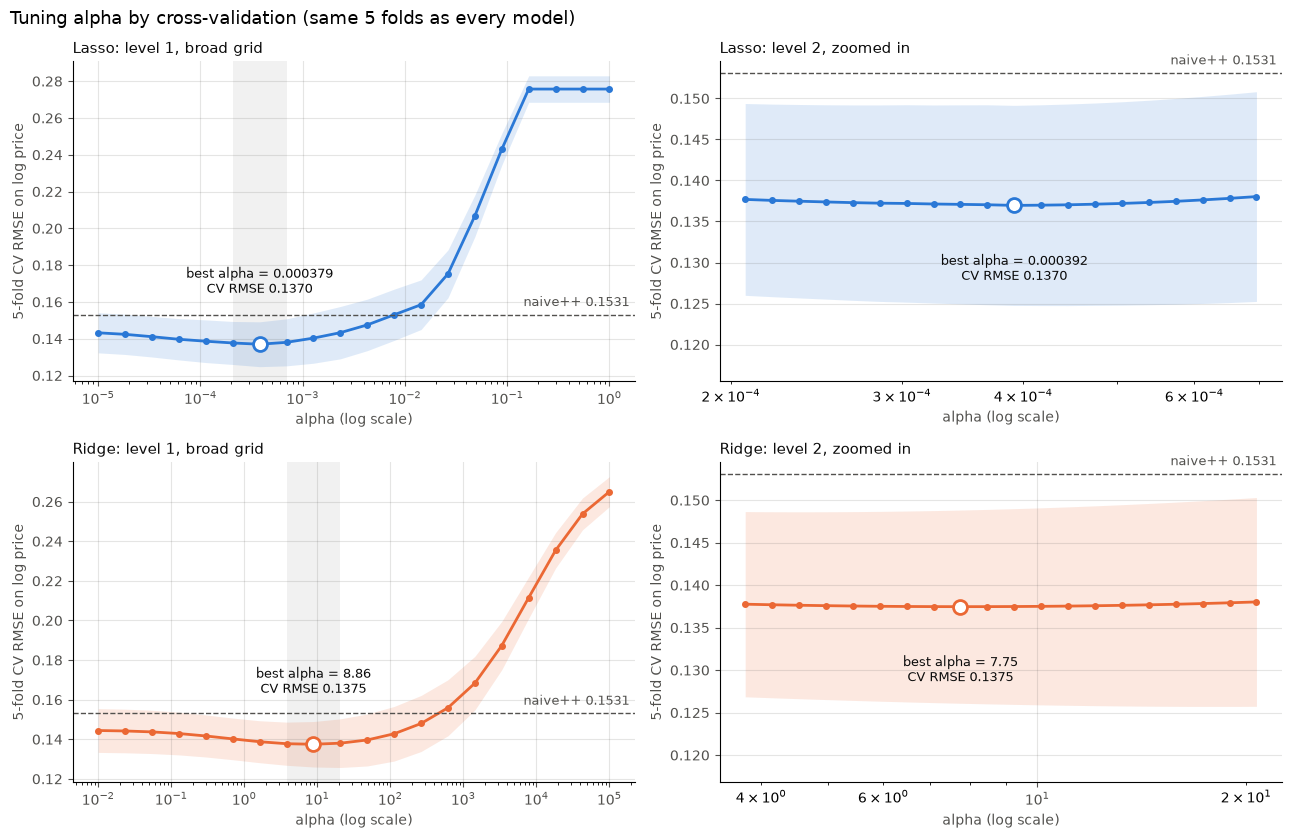

In [28]:
# tune alpha on all 1,460 training houses (the same 5 folds as every model), two levels per model
l_folds_all = prepare_folds(df_X_train, df_train['SalePrice'], kfold.split(df_X_train))
d_search = {name: two_level_search(name, l_folds_all) for name in ['Lasso', 'Ridge']}  # name -> (curve 1, curve 2, best alpha)
for name, (df_c1, df_c2, alpha) in d_search.items():
    print(f'{name}: best alpha {alpha:.3g}, CV RMSE there {df_c2.mean(axis=1).min():.4f} (the tuning-curve minimum: slightly optimistic)')

## chart: CV RMSE against alpha. Left: level 1 (broad grid; shaded = the range level 2 zooms into). Right: level 2.
## Band = ± 1 standard error of the 5-fold mean. Dashed line = naive++ on the same folds, for reference
cv_naive_pp = np.mean(d_cv['naive++ (log psf, fs10, OLS)'])
d_color = {'Lasso': '#2a78d6', 'Ridge': '#eb6834'}
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for r, (name, (df_c1, df_c2, alpha)) in enumerate(d_search.items()):
    for c, (df_c, level) in enumerate([(df_c1, 'level 1, broad grid'), (df_c2, 'level 2, zoomed in')]):
        ax = axes[r, c]
        sl_mean = df_c.mean(axis=1)
        sl_se = df_c.std(axis=1, ddof=1) / np.sqrt(df_c.shape[1])
        if c == 0:
            ax.axvspan(df_c2.index.min(), df_c2.index.max(), color='#52514e', alpha=0.08, linewidth=0)
        ax.fill_between(sl_mean.index, sl_mean - sl_se, sl_mean + sl_se, color=d_color[name], alpha=0.15, linewidth=0)
        ax.plot(sl_mean.index, sl_mean, '-o', color=d_color[name], linewidth=2, markersize=4)
        ax.axhline(cv_naive_pp, color='#52514e', linestyle='--', linewidth=1)
        ax.annotate(f'naive++ {cv_naive_pp:.4f}', (1, cv_naive_pp), xycoords=('axes fraction', 'data'),
                    xytext=(-4, 4), textcoords='offset points', ha='right', va='bottom', color='#52514e', fontsize=9)
        best = sl_mean.idxmin()
        ax.plot(best, sl_mean[best], 'o', color=d_color[name], markersize=10, markerfacecolor='white', markeredgewidth=2, zorder=3)
        ax.annotate(f'best alpha = {best:.3g}\nCV RMSE {sl_mean[best]:.4f}', (best, sl_mean[best]), xytext=(0, 34 if c == 0 else -34),
                    textcoords='offset points', ha='center', va='bottom' if c == 0 else 'top', color='#0b0b0b', fontsize=9)
        ax.set_xscale('log')
        ax.set_title(f'{name}: {level}', loc='left', fontsize=11, color='#0b0b0b')
        ax.set_xlabel('alpha (log scale)', color='#52514e')
        ax.set_ylabel('5-fold CV RMSE on log price', color='#52514e')
        ax.grid(color='#52514e', alpha=0.15, linewidth=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(colors='#52514e')
        if c == 1:  # leave room under the marker for its label
            lo, hi = ax.get_ylim()
            ax.set_ylim(lo - 0.25 * (hi - lo), hi)
fig.suptitle('Tuning alpha by cross-validation (same 5 folds as every model)', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.show()

In [29]:
# honest CV RMSE (nested CV): the whole two-level search is rerun inside each outer fold's 80% (on 5 inner folds of it),
# then the model is refit there at the alpha it picked and scored on the outer 20%. These are the numbers to log and compare
cv_rmse('Lasso (log psf, all features)', fit_predict_penalised('Lasso'))
cv_rmse('Ridge (log psf, all features)', fit_predict_penalised('Ridge'))

  Lasso: inner search picked alpha 0.000718
  Lasso: inner search picked alpha 0.000593
  Lasso: inner search picked alpha 0.00102
  Lasso: inner search picked alpha 0.000367
  Lasso: inner search picked alpha 0.000522
  Ridge: inner search picked alpha 10.1
  Ridge: inner search picked alpha 7.09
  Ridge: inner search picked alpha 13.2
  Ridge: inner search picked alpha 9.26
  Ridge: inner search picked alpha 10.1


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
"naive++ (log psf, fs10, OLS)",0.1578,0.1301,0.2064,0.1442,0.1270,0.1531,0.0288
"Lasso (log psf, all features)",0.1442,0.1183,0.1886,0.1245,0.1179,0.1387,0.0267
"Ridge (log psf, all features)",0.1434,0.1204,0.1813,0.1262,0.1178,0.1378,0.0235


In [30]:
# final models = (b): the alpha from the two-level search on all 1,460 houses (the chart above), refit on all of them (outliers dropped)
d_model_pen = {name: refit_penalised(name, alpha, df_X_train, df_train['SalePrice']) for name, (_, _, alpha) in d_search.items()}
d_pred_pen = {name: predict_penalised(model, df_X_test) for name, model in d_model_pen.items()}  # test-set sale prices

for name, model in d_model_pen.items():
    w = model[-1].coef_
    print(f"{name}: alpha {model[-1].alpha:.3g}, {np.sum(w != 0)} of {w.size} coefficients non-zero, L2 norm {np.linalg.norm(w):.3f}")

Lasso: alpha 0.000392, 117 of 268 coefficients non-zero, L2 norm 0.452
Ridge: alpha 7.75, 268 of 268 coefficients non-zero, L2 norm 0.445


Both penalised models beat the OLS baseline in every fold, by about 0.015 on average. Lasso and Ridge are within noise of each other (0.1387 vs 0.1378): Ridge wins folds 1, 3 and 5, Lasso folds 2 and 4. Lasso keeps 117 of 268 coefficients.

## Elastic Net

sklearn's `ElasticNet` minimises $\frac{1}{2n}\lVert y - Xw\rVert^2 + \lambda_1\lVert w\rVert_1 + \tfrac12\lambda_2\lVert w\rVert_2^2$, where $\lambda_1 = \alpha\cdot$`l1_ratio` and $\lambda_2 = \alpha\,(1 - $`l1_ratio`$)$. 

Tuning: a random search over $(\lambda_1, \lambda_2)$, drawn uniformly on the log scale, in two levels like Lasso/Ridge: 1,000 pairs in a broad box, then 500 within half a decade (on each axis) of the blend centre, where both penalties are about as strong as in the pure Lasso and Ridge fits. Scored with nested CV like every model.

In [31]:
# Elastic Net helpers: random search over (lambda_1, lambda_2), drawn log-uniformly, in two levels (broad box, then a box around the blend centre)
# sklearn's ElasticNet minimises (1/2n)·RSS + alpha·l1_ratio·|w|₁ + ½·alpha·(1 − l1_ratio)·|w|², so with
# lambda_1 = alpha·l1_ratio and lambda_2 = alpha·(1 − l1_ratio) the penalty is lambda_1·|w|₁ + ½·lambda_2·|w|²
d_model_cls['ElasticNet'] = ElasticNet
ui_en_n_draws = (1000, 500)  # random (lambda_1, lambda_2) pairs: level 1, level 2
ui_en_box = {'lambda_1': (1e-6, 1e-1), 'lambda_2': (1e-6, 1e1)}  # level 1: broad box; each axis's low end is ~pure Ridge (lambda_1) or ~pure Lasso (lambda_2)
ui_en_zoom = 0.5  # level 2: ± this many decades around the blend centre (Lasso's own alpha, Ridge's own alpha / n), on each axis
ui_en_seed = 42

def en_params(l1, l2):
    """(lambda_1, lambda_2) -> sklearn's (alpha, l1_ratio)."""
    return {'alpha': l1 + l2, 'l1_ratio': l1 / (l1 + l2)}

def draw_log_uniform(rng, box, n):
    """n random points, uniform on the log scale within box = {axis: (low, high)}."""
    return pd.DataFrame({k: 10 ** rng.uniform(np.log10(lo), np.log10(hi), n) for k, (lo, hi) in box.items()})

def en_fold_rmses(l1, l2, l_folds):
    """One (lambda_1, lambda_2) pair: CV RMSE on log price in each fold."""
    l_rmse = []
    for f in l_folds:
        ## max_iter: pairs near the box's bottom-left corner (both penalties tiny) are close to an unpenalised OLS on ~270 correlated
        ## columns, where coordinate descent converges slowly; fits that converge sooner stop early, so only those pay for it
        m = ElasticNet(**en_params(l1, l2), max_iter=200_000, precompute=True).fit(f['X_tr'], f['y_tr'])
        l_rmse.append(rmse_log_price(np.exp(m.predict(f['X_va'])) * f['area_va'], f['price_va']))
    return l_rmse

def cv_points(df_pts, l_folds):
    """CV RMSE for every pair in df_pts (columns lambda_1, lambda_2), run in parallel: adds one column per fold and the mean."""
    rows = Parallel(n_jobs=-1)(delayed(en_fold_rmses)(l1, l2, l_folds) for l1, l2 in df_pts[['lambda_1', 'lambda_2']].itertuples(index=False))
    df = df_pts.join(pd.DataFrame(rows, index=df_pts.index, columns=[f'fold {k + 1}' for k in range(len(l_folds))]))
    df['mean'] = df.filter(like='fold').mean(axis=1)
    return df

def en_centre(l_folds):
    """The blend centre: each penalty at the strength its pure model picks on these folds (Lasso's alpha is a lambda_1;
    Ridge minimises RSS + alpha·|w|², which divided by 2n is (1/2n)·RSS + ½·(alpha/n)·|w|², so Ridge's alpha / n is a lambda_2)."""
    n_fit = np.mean([f['X_tr'].shape[0] for f in l_folds])
    return {'lambda_1': two_level_search('Lasso', l_folds)[2], 'lambda_2': two_level_search('Ridge', l_folds)[2] / n_fit}

def random_search_en(l_folds, n_draws=ui_en_n_draws, seed=ui_en_seed):
    """Level 1: random pairs in the broad box, a map of the whole surface. Level 2: random pairs within ± ui_en_zoom decades of the
    blend centre, where both penalties are about as strong as each pure model wants them. The pick is the best LEVEL-2 pair, so the
    final model is a real blend rather than a Lasso with a trace of Ridge (the surface is flat enough to afford it: see the notes below).
    Returns (level-1 table, level-2 table, best level-2 (lambda_1, lambda_2))."""
    rng = np.random.default_rng(seed)
    df_s1 = cv_points(draw_log_uniform(rng, ui_en_box, n_draws[0]), l_folds)
    box2 = {k: (v / 10 ** ui_en_zoom, v * 10 ** ui_en_zoom) for k, v in en_centre(l_folds).items()}
    df_s2 = cv_points(draw_log_uniform(rng, box2, n_draws[1]), l_folds)
    best = df_s2.loc[df_s2['mean'].idxmin()]
    return df_s1, df_s2, (best['lambda_1'], best['lambda_2'])

def fit_predict_en(df_X_tr, sl_price_tr, df_X_va):
    """For cv_rmse (nested CV): on each outer fold's 80%, run the two-level random search on 5 inner folds, refit at the best pair, predict the 20%."""
    inner = KFold(n_splits=ui_n_folds, shuffle=True, random_state=42).split(df_X_tr)
    _, _, (l1, l2) = random_search_en(prepare_folds(df_X_tr, sl_price_tr, inner))
    print(f'  Elastic Net: inner search picked lambda_1 {l1:.3g}, lambda_2 {l2:.3g} (alpha {l1 + l2:.3g}, l1_ratio {l1 / (l1 + l2):.2f})')
    return predict_penalised(refit_penalised('ElasticNet', l1 + l2, df_X_tr, sl_price_tr, l1_ratio=l1 / (l1 + l2)), df_X_va)

Elastic Net, level-1 best (whole box, for reference): lambda_1 0.000393, lambda_2 4e-06 (l1_ratio 0.99), CV RMSE 0.1370
Elastic Net, chosen = level-2 best (blend box): lambda_1 0.000135, lambda_2 0.00262 (alpha 0.00275, l1_ratio 0.05), CV RMSE there 0.1374 (the best of 500 noisy scores: optimistic)


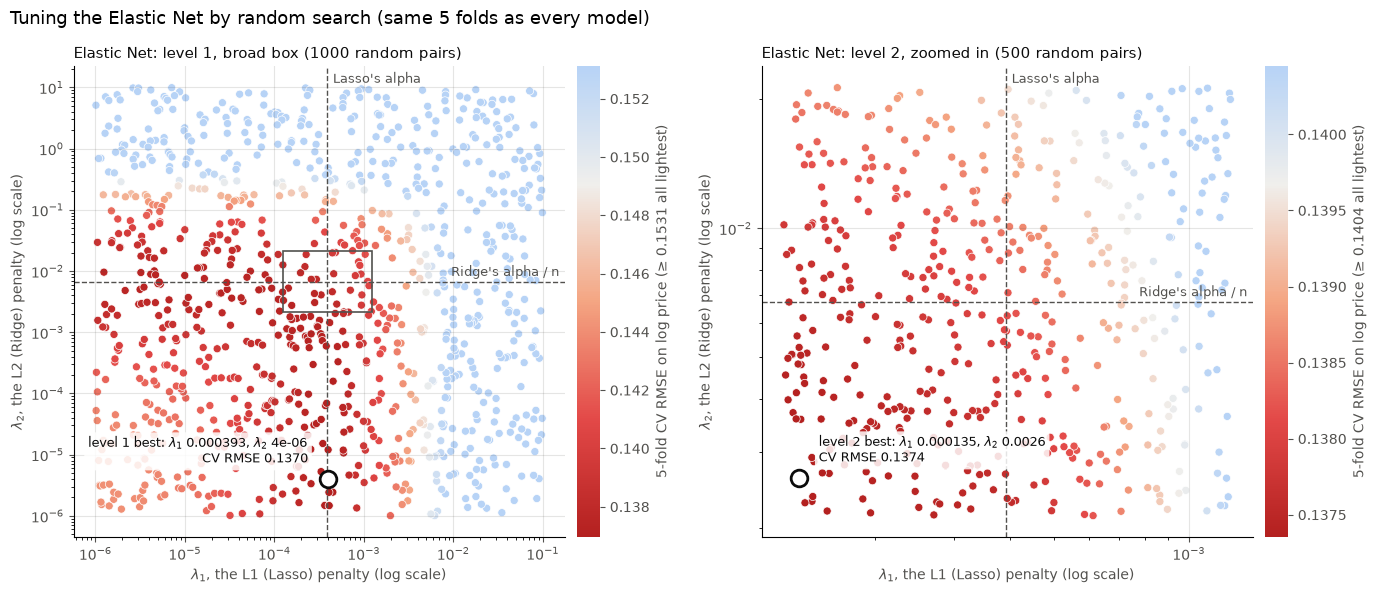

In [32]:
# tune (lambda_1, lambda_2) on all 1,460 training houses (the same 5 folds as every model): two-level random search
df_en_s1, df_en_s2, (en_l1, en_l2) = random_search_en(l_folds_all)
best1 = df_en_s1.loc[df_en_s1['mean'].idxmin()]
print(f"Elastic Net, level-1 best (whole box, for reference): lambda_1 {best1['lambda_1']:.3g}, lambda_2 {best1['lambda_2']:.3g} "
      f"(l1_ratio {best1['lambda_1'] / (best1['lambda_1'] + best1['lambda_2']):.2f}), CV RMSE {best1['mean']:.4f}")
print(f'Elastic Net, chosen = level-2 best (blend box): lambda_1 {en_l1:.3g}, lambda_2 {en_l2:.3g} (alpha {en_l1 + en_l2:.3g}, l1_ratio {en_l1 / (en_l1 + en_l2):.2f}), '
      f'CV RMSE there {df_en_s2["mean"].min():.4f} (the best of {ui_en_n_draws[1]} noisy scores: optimistic)')

## chart: every random pair at (lambda_1, lambda_2), coloured by its CV RMSE (redder = lower). Left: level 1 (box = level 2, around the blend centre where the guides cross). Right: level 2.
## Dashed guides = the pure models' own best penalties in these units: Lasso's alpha is a lambda_1; Ridge's alpha / n is a lambda_2
## (Ridge minimises RSS + alpha·|w|²; divided by 2n that is (1/2n)·RSS + ½·(alpha/n)·|w|²). Pure Lasso sits at lambda_2 = 0, below the chart; pure Ridge at lambda_1 = 0, left of it
cmap_en = LinearSegmentedColormap.from_list('cold_to_hot', ['#b3201f', '#e34948', '#f4a582', '#f0efec', '#b7d3f6'])  # hot red = lowest RMSE (best), light blue = worst
n_fit = np.mean([f['X_tr'].shape[0] for f in l_folds_all])  # training rows per fold, after the outlier drop
d_guides = {'lambda_1': (d_search['Lasso'][2], "Lasso's alpha"), 'lambda_2': (d_search['Ridge'][2] / n_fit, "Ridge's alpha / n")}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, df_s, level, vmax in [(axes[0], df_en_s1, 'level 1', cv_naive_pp), (axes[1], df_en_s2, 'level 2', df_en_s2['mean'].quantile(0.9))]:
    df_s = df_s.sort_values('mean', ascending=False)  # best points drawn last, on top
    norm = Normalize(vmin=df_s['mean'].min(), vmax=vmax, clip=True)
    sc = ax.scatter(df_s['lambda_1'], df_s['lambda_2'], c=df_s['mean'], cmap=cmap_en, norm=norm, s=34, edgecolors='white', linewidths=0.5)
    cb = fig.colorbar(sc, ax=ax, pad=0.02)
    cb.set_label(f'5-fold CV RMSE on log price (≥ {vmax:.4f} all lightest)', color='#52514e')
    cb.ax.tick_params(colors='#52514e')
    cb.outline.set_visible(False)
    best = df_s.iloc[-1]
    left = np.log(best['lambda_1']) < np.log(df_s['lambda_1']).mean()  # label on the side with more room
    ax.plot(best['lambda_1'], best['lambda_2'], 'o', color='#0b0b0b', markersize=12, markerfacecolor='white', markeredgewidth=2, zorder=3)
    ax.annotate(f"{level} best: $\\lambda_1$ {best['lambda_1']:.3g}, $\\lambda_2$ {best['lambda_2']:.2g}\nCV RMSE {best['mean']:.4f}", (best['lambda_1'], best['lambda_2']),
                xytext=(14 if left else -14, 12), textcoords='offset points', ha='left' if left else 'right', color='#0b0b0b', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='none', alpha=0.85))
    if df_s['lambda_1'].min() < d_guides['lambda_1'][0] < df_s['lambda_1'].max():  # guides only where the points are
        ax.axvline(d_guides['lambda_1'][0], color='#52514e', linestyle='--', linewidth=1)
        ax.annotate(d_guides['lambda_1'][1], (d_guides['lambda_1'][0], 1), xycoords=('data', 'axes fraction'), xytext=(4, -4), textcoords='offset points', va='top', color='#52514e', fontsize=9)
    if df_s['lambda_2'].min() < d_guides['lambda_2'][0] < df_s['lambda_2'].max():
        ax.axhline(d_guides['lambda_2'][0], color='#52514e', linestyle='--', linewidth=1)
        ax.annotate(d_guides['lambda_2'][1], (1, d_guides['lambda_2'][0]), xycoords=('axes fraction', 'data'), xytext=(-4, 4), textcoords='offset points', ha='right', color='#52514e', fontsize=9)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.xaxis.set_minor_formatter(NullFormatter())  # no overlapping minor tick labels on the zoomed panel
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_title(f"Elastic Net: {level}, {'broad box' if level == 'level 1' else 'zoomed in'} ({len(df_s)} random pairs)", loc='left', fontsize=11, color='#0b0b0b')
    ax.set_xlabel(r'$\lambda_1$, the L1 (Lasso) penalty (log scale)', color='#52514e')
    ax.set_ylabel(r'$\lambda_2$, the L2 (Ridge) penalty (log scale)', color='#52514e')
    ax.grid(color='#52514e', alpha=0.15, linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors='#52514e')
lo1, hi1 = df_en_s2['lambda_1'].min(), df_en_s2['lambda_1'].max()
lo2, hi2 = df_en_s2['lambda_2'].min(), df_en_s2['lambda_2'].max()
axes[0].add_patch(Rectangle((lo1, lo2), hi1 - lo1, hi2 - lo2, fill=False, edgecolor='#52514e', linewidth=1.2))
fig.suptitle('Tuning the Elastic Net by random search (same 5 folds as every model)', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.show()

In [33]:
# honest CV RMSE (nested CV): the whole two-level random search is rerun inside each outer fold's 80% (on 5 inner folds of it),
# then the model is refit there at the pair it picked and scored on the outer 20%. This is the number to log and compare
cv_rmse('Elastic Net (log psf, all features)', fit_predict_en)

  Elastic Net: inner search picked lambda_1 0.000495, lambda_2 0.00352 (alpha 0.00402, l1_ratio 0.12)
  Elastic Net: inner search picked lambda_1 0.000191, lambda_2 0.00522 (alpha 0.00541, l1_ratio 0.04)
  Elastic Net: inner search picked lambda_1 0.00085, lambda_2 0.00473 (alpha 0.00558, l1_ratio 0.15)
  Elastic Net: inner search picked lambda_1 0.000118, lambda_2 0.00679 (alpha 0.00691, l1_ratio 0.02)
  Elastic Net: inner search picked lambda_1 0.000435, lambda_2 0.00362 (alpha 0.00406, l1_ratio 0.11)


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
"naive++ (log psf, fs10, OLS)",0.1578,0.1301,0.2064,0.1442,0.1270,0.1531,0.0288
"Lasso (log psf, all features)",0.1442,0.1183,0.1886,0.1245,0.1179,0.1387,0.0267
"Ridge (log psf, all features)",0.1434,0.1204,0.1813,0.1262,0.1178,0.1378,0.0235
"Elastic Net (log psf, all features)",0.1438,0.1186,0.1881,0.1258,0.1180,0.1389,0.0263


In [34]:
# final model = (b): the pair from the random search on all 1,460 houses (the chart above), refit on all of them (outliers dropped)
d_model_pen['ElasticNet'] = refit_penalised('ElasticNet', en_l1 + en_l2, df_X_train, df_train['SalePrice'], l1_ratio=en_l1 / (en_l1 + en_l2))
d_pred_pen['ElasticNet'] = predict_penalised(d_model_pen['ElasticNet'], df_X_test)  # test-set sale prices

w = d_model_pen['ElasticNet'][-1].coef_
print(f"Elastic Net: lambda_1 {en_l1:.3g}, lambda_2 {en_l2:.3g}, {np.sum(w != 0)} of {w.size} coefficients non-zero, L2 norm {np.linalg.norm(w):.3f}")
print(f"test predictions: correlation with Lasso's {np.corrcoef(np.log(d_pred_pen['ElasticNet']), np.log(d_pred_pen['Lasso']))[0, 1]:.5f}, "
      f"with Ridge's {np.corrcoef(np.log(d_pred_pen['ElasticNet']), np.log(d_pred_pen['Ridge']))[0, 1]:.5f}")

Elastic Net: lambda_1 0.000135, lambda_2 0.00262, 183 of 268 coefficients non-zero, L2 norm 0.446
test predictions: correlation with Lasso's 0.99925, with Ridge's 0.99980


What the search shows. Level 1 maps the whole box. The low-error region is an L-shaped valley with two arms:
* a Lasso arm: $\lambda_1 \approx$ Lasso's $\alpha$, with $\lambda_2$ close to 0;
* a Ridge arm: $\lambda_2 \approx$ Ridge's $\alpha/n$, with $\lambda_1$ close to 0.

The valley is flat. Its lowest point (the Lasso end, 0.1370) is only about 0.0005 better than the Ridge arm and the blends near where the two guides cross.

Why level 2 searches the blend region. With the luxury of this map, a pure-Lasso pick isn't worth much: it is within noise of the rest of the valley, and it would just reproduce the Lasso. So level 2 deliberately searches around the blend centre, where the two guides cross (each penalty at the strength its pure model picks), $\pm$ half a decade on each axis, and the final pair is the best of level 2. Both penalties then stay within about $3\times$ of their solo strengths: a genuine blend, rather than a Lasso with a trace of Ridge. The centre is recomputed from the folds inside each search, so the nested CV still never sees its outer validation folds.

Result:
* On all 1,460 houses, level 2 picks $\lambda_1 = 0.000135$ and $\lambda_2 = 0.0026$ (`l1_ratio` 0.05). That is an L1 penalty about a third of Lasso's and an L2 penalty about 40% of Ridge's, near the box's weaker-penalty corner. It keeps 183 of 268 coefficients (Lasso 117, Ridge all 268), and its test predictions sit between the two (correlation 0.9993 with Lasso's, 0.9998 with Ridge's).
* Inside the nested CV, all five inner searches picked a blend too (`l1_ratio` 0.02–0.15).
* Nested CV RMSE 0.1389: level with Lasso (0.1387) and Ridge (0.1378), all within noise. The blend costs nothing measurable, but it doesn't gain anything either.

## Model comparison and final choice

In [35]:
# all four models on the same 5 folds (RMSE of log price); the penalised models' scores are nested CV
df_cv = pd.DataFrame(d_cv, index=[f'fold {k + 1}' for k in range(kfold.get_n_splits())]).T
df_cv.assign(mean=df_cv.mean(axis=1), sd=df_cv.std(axis=1, ddof=0)).round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
"naive++ (log psf, fs10, OLS)",0.1578,0.1301,0.2064,0.1442,0.1270,0.1531,0.0288
"Lasso (log psf, all features)",0.1442,0.1183,0.1886,0.1245,0.1179,0.1387,0.0267
"Ridge (log psf, all features)",0.1434,0.1204,0.1813,0.1262,0.1178,0.1378,0.0235
"Elastic Net (log psf, all features)",0.1438,0.1186,0.1881,0.1258,0.1180,0.1389,0.0263


| Model | CV RMSE (5 folds) | Kaggle public score* |
|---|---|---|
| naive++ (forward selection → OLS) | 0.1531 | 0.15408 |
| Lasso | 0.1387 | 0.14092 |
| Ridge | 0.1378 | 0.13809 |
| Elastic Net (blended) | 0.1389 | 0.13895 |

\* Public scores of this version, submitted on 27 Oct 2026 after the final model had been chosen.

My final choice for the model is the one with the lowest CV RMSE - not the best Kaggle score. The public leaderboard is a test set. Choosing by it would tune the model to that particular split, whereas the CV score is the ex-ante estimate of out-of-sample error.

Final model: Ridge ($\alpha$ = 7.75), refit on all 1,460 training houses with the outliers dropped. Notes:
* Lasso (0.1387) and the blended Elastic Net (0.1389) are within noise of it (fold SDs about 0.025).
* All three penalised models beat the OLS baseline, in every fold.
* **Major caveat**: The order of the three depends on the fold split (noting that with `random_state=0`, Lasso came first). The rule still picks one model before seeing the test set, but the honest reading is that the three are largely comparable here.
* Ridge is the preferred model regardless of the Kaggle scores. They were looked at only after the choice was made, so they don't feed into it.

## Predict and export

In [36]:
# final model: Ridge (lowest CV RMSE), refit on all 1,460 training houses at the alpha tuned above -> SalePrice for test.csv
export = False

if export == True:
    sl_pred_final = d_pred_pen['Ridge']
    df_sub = pd.DataFrame({'Id': df_test['Id'], 'SalePrice': sl_pred_final})

    ## sanity checks before writing
    assert sl_pred_final.index.equals(df_test.index)  # same row order as test.csv
    assert len(df_sub) == 1459 and df_sub['SalePrice'].notna().all() and (df_sub['SalePrice'] > 0).all()
    print(df_sub['SalePrice'].describe().round(0))

    path_sub = ROOT / "submissions" / "22DM012-assn01-jx_ridge.csv"
    path_sub.parent.mkdir(exist_ok=True)
    df_sub.to_csv(path_sub, index=False)
    print("saved", path_sub)